In [2]:
# Data libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import sklearn.pipeline
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import PolynomialFeatures
from sklearn.compose import make_column_transformer
from sklearn.linear_model import Ridge

labels = ["avg", "min", "max"]
cutoff = pd.Timestamp("2026-08-31")

In [3]:
def reshape_long(avg_df, min_df, max_df, loc_df, start = "2017-04-01", drop_tidal = True):
    """
    Input:
    - avg_df, min_df, max_df: Average, Minimum and Maximum df
    - loc_df: locations df
    - start: observations before this date will be removed
    - drop_tidal: boolean value, should tidal-level stations be removed
    Returns: 
    - river long df: df with one row per station per day and columns
    """
    data = [avg_df, min_df, max_df]  
    column = ["County", "Station_Name", "Observation_ID", "date"]
    long_df = {}

    for df, lab in zip(data, labels):
        if drop_tidal:
            df = df[~df["Observation_ID"].str.contains("tidal-level", na = False)]  
        
        long_df[lab] = df.melt(id_vars = column[0:3], var_name = "date", value_name = lab)
        long_df[lab]["date"] = pd.to_datetime(long_df[lab]["date"], format = "%d/%m/%Y")
        long_df[lab] = long_df[lab][long_df[lab]["date"] >= start]

    river_long = (long_df["avg"]
                 .merge(long_df["min"], on = column, how = "left")
                 .merge(long_df["max"], on = column, how = "left"))

    n_before = len(river_long)
    
    river_long = river_long.merge(loc_df, on = column[0:3], how = "left")

    assert len(river_long) == n_before, "location merged duplicated rows"

    print(f"Number of missing latitude: {river_long['Latitude'].isna().sum()}")
    print(f"Number of missing longitude: {river_long['Longitude'].isna().sum()}")

    for col in column[0:3]:
        river_long[col] = river_long[col].astype("category")

    
    return river_long

In [4]:
def clean_error(df, k = 20):
    """
    Input: 
    - df: long data frame that contains Observation_ID, date, avg, min, max
    - k: number of IQRs beyond Q1/Q3 at which a value is an outlier
    Returns:
    - df2 : a copy of the df with the bad values replaced by NaN values
    """
    df2 = df.copy()

    large_vals = df2[labels].isin([99999.999, -999999.999, -99]) | (df2[labels].abs() >= 9999)

    df2[labels] = df2[labels].where(~large_vals, np.nan)

    for lab in labels:
        train_val = df2[lab].where(df2["date"] <= cutoff)
        per_sta = train_val.groupby(df2["Observation_ID"], observed = True)

        q1 = per_sta.transform(lambda s: s.quantile(0.25))
        q3 = per_sta.transform(lambda s: s.quantile(0.75))
        sd = per_sta.transform("std")

        # if iqr = 0 we use std
        iqr = (q3 - q1).where(q3 - q1 > 0, sd)
        
        outlier = ((df2[lab] > q3 + k * iqr) | (df2[lab] < q1 - k * iqr))
        
        
        df2.attrs[f"sentinel_{lab}"] = int(large_vals[lab].sum())
        df2.attrs[f"outliers_{lab}"] = int(outlier.sum())    

        df2.attrs[f"outlier_{lab}_test"] = int((outlier & (df2["date"] > cutoff)).sum())
        df2.loc[outlier& (df2["date"] <= cutoff), lab] = np.nan




    bad = (df2["min"] > df2["avg"]) | (df2["avg"] > df2["max"])
    df2.attrs["order_violations"] = int(bad.sum())
    df2.loc[bad, labels] = np.nan
        
    return df2

In [5]:
def drop_ids(df, min_years = 3, cutoff = cutoff, recent_from="2026-06-01"):
    """
    Input:
    - df: long cleaned data fram: contains Observation_ID, date, avg
    - min_years: minimum number of years of non missing avg data a station needs to be kept
    cutoff: data that marks the end of the period (given from the question)
    Return:
    - keep_df: a copy of df containing only stations we keep
    """
    train_obs = df["avg"].notna() & (df["date"] <= pd.Timestamp(cutoff))
    years = train_obs.groupby(df["Observation_ID"], observed = True).sum() / 365.25


    keep_ids = years[years >= min_years].index

    keep_df = df[df["Observation_ID"].isin(keep_ids)].copy()
    keep_df.attrs["dropped_ids"] = int((years < min_years).sum())
    keep_df.attrs["kept_ids"] = int((years >= min_years).sum())

    return keep_df

In [6]:
def make_split(clean_df, cutoff = "2026-08-31",
               feature_cols = ["Latitude", "Longitude"], target = "avg"):
    """
    Input:
    - clean_df: a long data frame containing  Observation_ID, date, the feature columns and the target column
    - cutoff: last day of training period
    - feature_cols: list of features names
    - target: target name to preidct
    Returns:
    - X_train
    - y_train
    - X_test
    - y_test
    """
    cutoff = pd.Timestamp(cutoff)

    # split by cutoff date
    train = clean_df[clean_df["date"] <= cutoff]
    test  = clean_df[clean_df["date"] > cutoff]

    # drop rows with no target, then sort + renumber
    train = train.dropna(subset = [target]).sort_values(["Observation_ID", "date"]).reset_index(drop = True)
    test  = test.dropna(subset = [target]).sort_values(["Observation_ID", "date"]).reset_index(drop = True)

    X_train, y_train = train[feature_cols], train[target]
    X_test,  y_test  = test[feature_cols],  test[target]

    return X_train, y_train, X_test, y_test

In [7]:
# claude suggested we use cosine and sine for periodicity
def add_features(df, cutoff = cutoff):
    """
    Input:
    - df: a long dataframe containing  containing Observation_ID, date and avg
    Returns:
    - df2: a copy of df with columns added:
            * sta_mean: stations mean avg level
            * sta_std: stations stdev avg level
            * z: standardised level
            * sin_doy, cos_doy: sin and cos of the day od the year scaled to one full cycle per year
    """
    df2 = df.copy()    
    train_val = df2["avg"].where(df2["date"] <= cutoff)
    per_sta = train_val.groupby(df2["Observation_ID"], observed = True)
    
    df2["sta_mean"] = per_sta.transform("mean")
    df2["sta_std"] = per_sta.transform("std")
    sigma = df2.groupby("Observation_ID", observed = True)["sta_std"].first()
    #print("Stations with sigma = 0 or NaN:", ((sigma == 0) | sigma.isna()).sum())
    #print("Stations with smallest sigma values:", sigma.nsmallest(5))
    
    df2["z"] = (df2["avg"] - df2["sta_mean"]) / df2["sta_std"]
    infinite_z = np.isinf(df2["z"]).sum()
    #print("Stations with infinite z values:", infinite_z)

    doy = df2["date"].dt.dayofyear
    df2["sin_doy"] = np.sin(2 * np.pi * doy / 365.25)
    df2["cos_doy"] = np.cos(2 * np.pi * doy / 365.25)
    #print("Median sigma:", sigma.median())
    return df2


In [8]:
def make_fold(df, year):
    c = pd.Timestamp(f"{year}-08-31")
    v_end = pd.Timestamp(f"{year}-11-30")
    df_k = drop_ids(df, min_years = 3, cutoff = c)
    feat = add_features(df_k, cutoff = c)
    fit = feat[feat["date"] <= c]
    val = feat[(feat["date"] > c) & (feat["date"] <= v_end)]
    fit, val = fit.dropna(subset = ["z"]), val.dropna(subset = ["z"])
    return fit, val

def cv_score(model, df, years, features, target = "z", n_sub = None):
    scores = np.zeros(len(years))
    for i, y in enumerate(years):
        fit, val = make_fold(df, y)
        if n_sub is not None:
            fit = fit.sample(n=n_sub, random_state = 0)
        model.fit(fit[features], fit[target])
        pred = model.predict(val[features])
        rmse = root_mean_squared_error(val[target], pred)
        scores[i] = rmse

    return scores

In [9]:
# Load data

river_avg = pd.read_csv("avg_river_levels.csv")
river_min = pd.read_csv("min_river_levels.csv")
river_max = pd.read_csv("max_river_levels.csv")

river_location = pd.read_csv("monitoring_locations.csv")

# Data cleaning

river_long = reshape_long(river_avg, river_min, river_max, river_location)
river_long2 = clean_error(river_long)
river_long3 = drop_ids(river_long2)

print(river_long2.attrs)
print(river_long3.attrs)

Number of missing latitude: 0
Number of missing longitude: 0
{'sentinel_avg': 76, 'outliers_avg': 112, 'outlier_avg_test': 1, 'sentinel_min': 32, 'outliers_min': 179, 'outlier_min_test': 5, 'sentinel_max': 47, 'outliers_max': 145, 'outlier_max_test': 0, 'order_violations': 0}
{'sentinel_avg': 76, 'outliers_avg': 112, 'outlier_avg_test': 1, 'sentinel_min': 32, 'outliers_min': 179, 'outlier_min_test': 5, 'sentinel_max': 47, 'outliers_max': 145, 'outlier_max_test': 0, 'order_violations': 0, 'dropped_ids': 8, 'kept_ids': 372}


In [10]:
train_df = river_long3[river_long3["date"] <= cutoff].copy()
train_df.info()
train_df[labels].describe()
train_df[labels].isna().sum()

print("Stations:", train_df["Observation_ID"].nunique())
print("Counties:", train_df["County"].nunique())
print("Dates:", train_df["date"].min().date(), "to", train_df["date"].max().date())

<class 'pandas.core.frame.DataFrame'>
Index: 1279680 entries, 0 to 1307199
Data columns (total 9 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   County          1279680 non-null  category      
 1   Station_Name    1279680 non-null  category      
 2   Observation_ID  1279680 non-null  category      
 3   date            1279680 non-null  datetime64[ns]
 4   avg             1129125 non-null  float64       
 5   min             1129105 non-null  float64       
 6   max             1129121 non-null  float64       
 7   Latitude        1279680 non-null  float64       
 8   Longitude       1279680 non-null  float64       
dtypes: category(3), datetime64[ns](1), float64(5)
memory usage: 74.5 MB
Stations: 372
Counties: 35
Dates: 2017-04-01 to 2026-08-31


Here, we do some EDA

In [11]:
train_df = train_df.sort_values(["Observation_ID", "date"]).copy()
per_sta = train_df.groupby("Observation_ID", observed = True)["avg"]
train_df["z"] = (train_df["avg"] - per_sta.transform("mean")) / per_sta.transform("std")
train_df["year"] = train_df["date"].dt.year
train_df["month"] = train_df["date"].dt.month
train_df["doy"] = train_df["date"].dt.dayofyear

There are still missing values, we need to find another soln

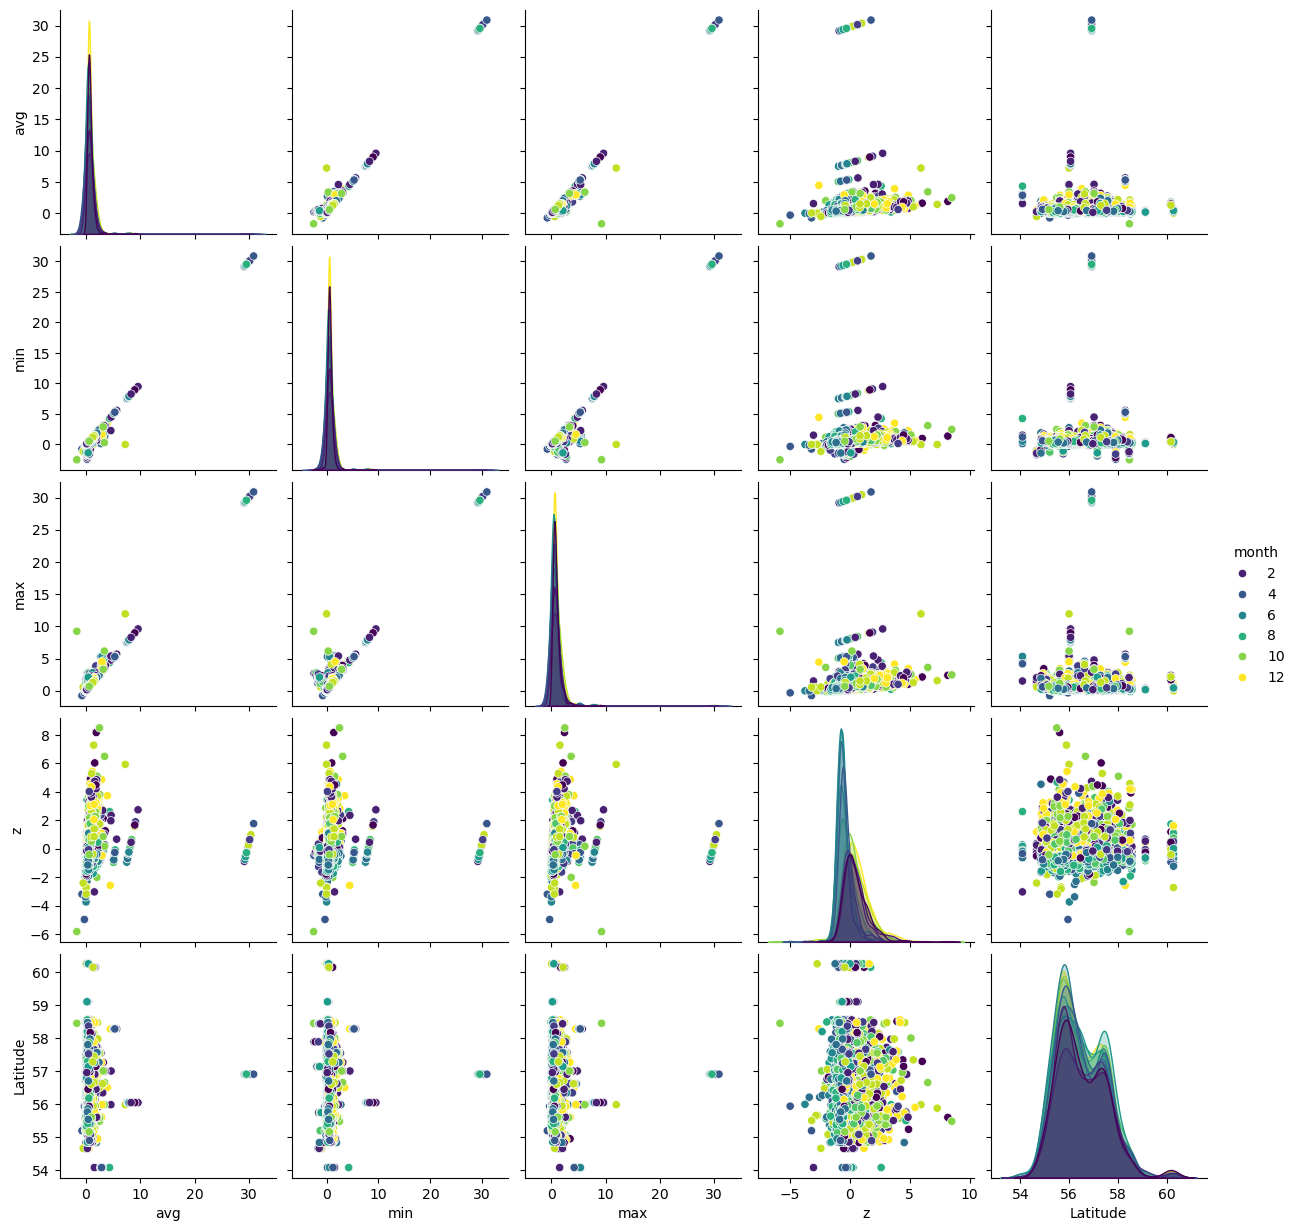

In [12]:
sample = train_df.dropna(subset = ["avg"]).sample(5000, random_state = 0)
sns.pairplot(sample, vars = ["avg", "min", "max", "z", "Latitude"], hue = "month", palette = "viridis")
plt.show()

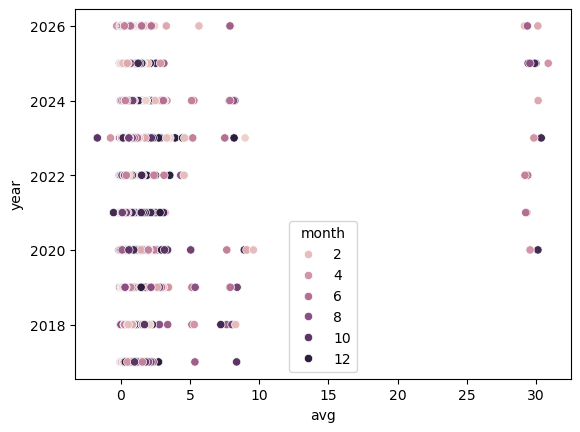

In [13]:
sns.scatterplot(data = sample, x = "avg", y="year", hue="month")
plt.show()

Now, we do some EDA

In [14]:
train_df = train_df.sort_values(["Observation_ID", "date"]).copy()
per_sta = train_df.groupby("Observation_ID", observed = True)["avg"]
train_df["z"] = (train_df["avg"] - per_sta.transform("mean")) / per_sta.transform("std")
train_df["year"] = train_df["date"].dt.year
train_df["month"] = train_df["date"].dt.month
train_df["doy"] = train_df["date"].dt.dayofyear

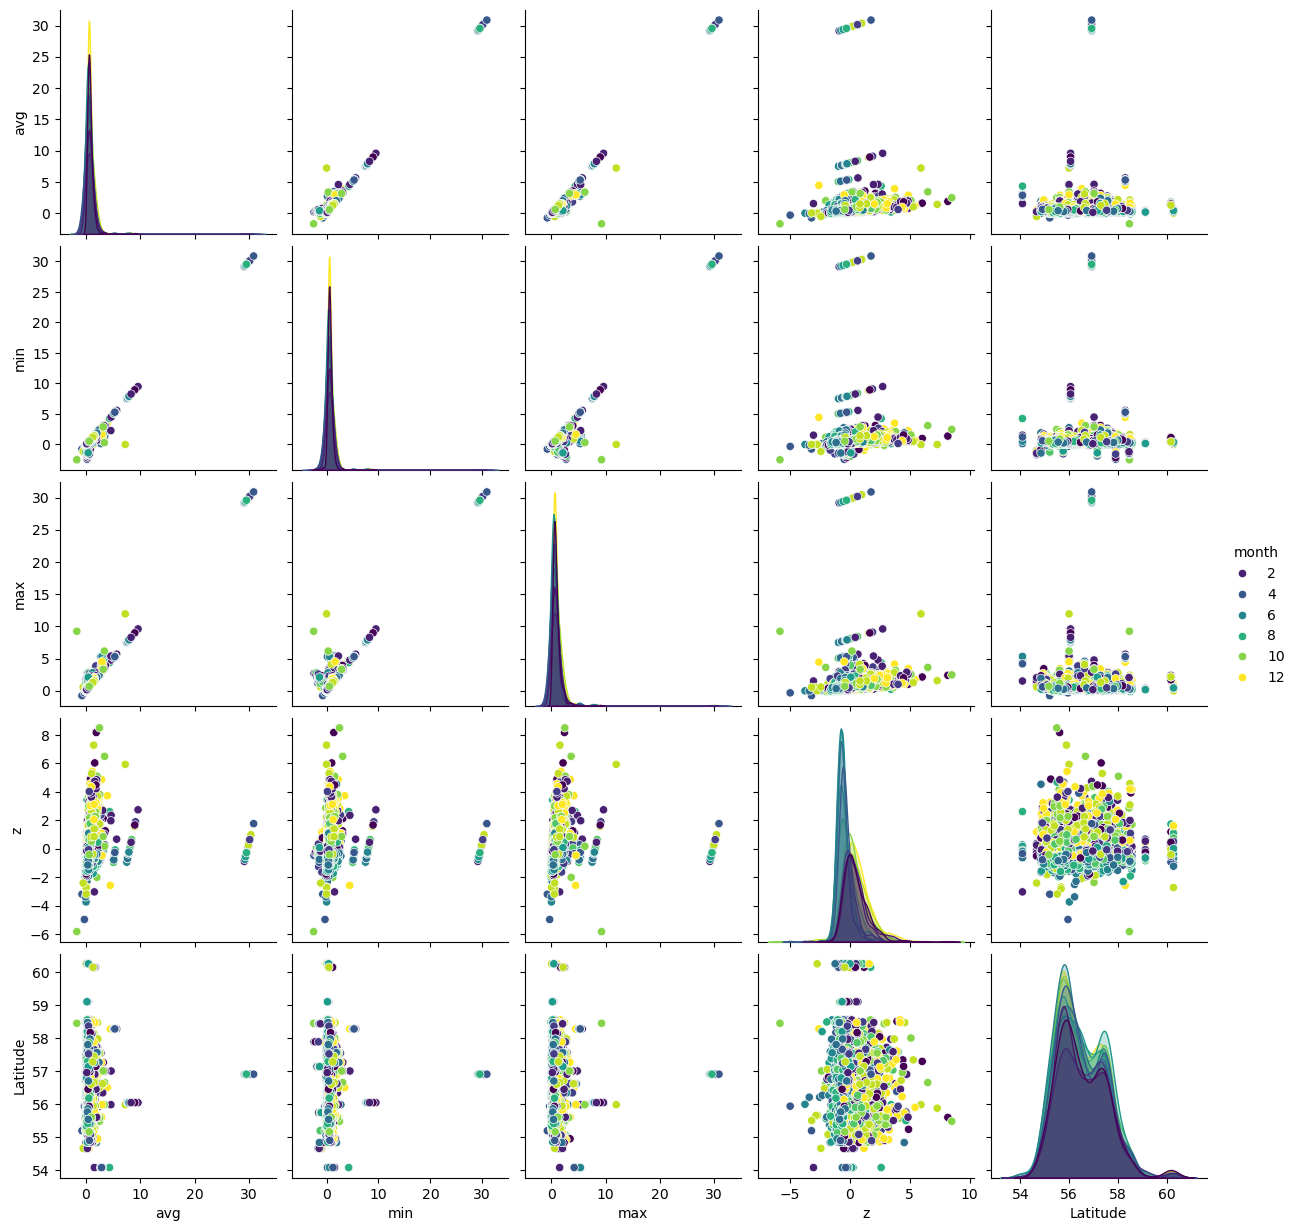

In [15]:
sample = train_df.dropna(subset = ["avg"]).sample(5000, random_state = 0)
sns.pairplot(sample, vars = ["avg", "min", "max", "z", "Latitude"], hue = "month", palette = "viridis")
plt.show()

Daily min, avd, and max levels are linearly related.
Latidue has no clear relation with z.

In [16]:
sample.columns

Index(['County', 'Station_Name', 'Observation_ID', 'date', 'avg', 'min', 'max',
       'Latitude', 'Longitude', 'z', 'year', 'month', 'doy'],
      dtype='object')

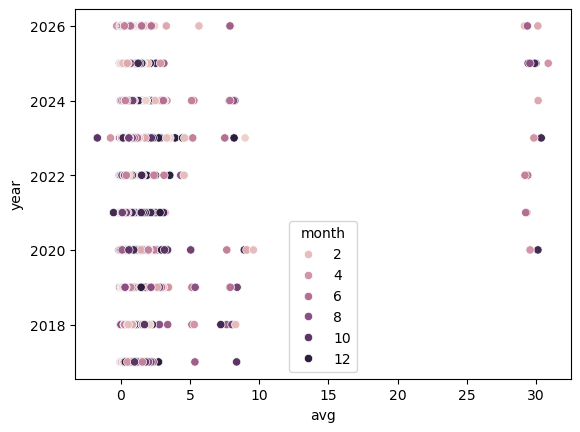

In [17]:
sns.scatterplot(data = sample, x = "avg", y="year", hue="month")
plt.show()

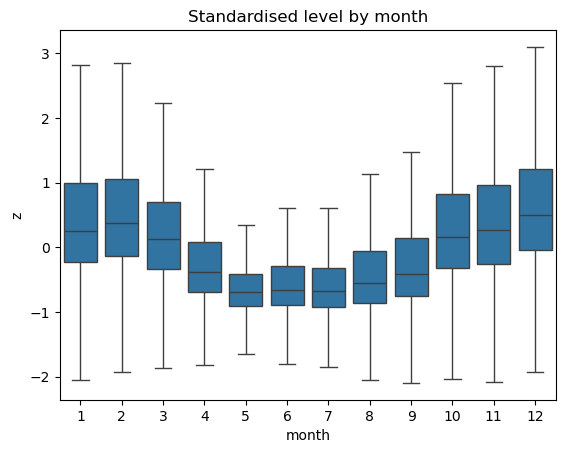

In [18]:
sns.boxplot(data = train_df, x = "month", y = "z", showfliers = False)
plt.title("Standardised level by month")

plt.show()

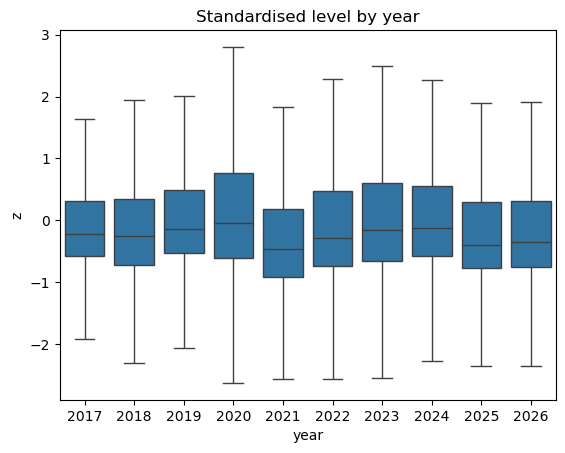

In [19]:
sns.boxplot(data = train_df, x = "year", y = "z", showfliers = False)
plt.title("Standardised level by year")
plt.show()

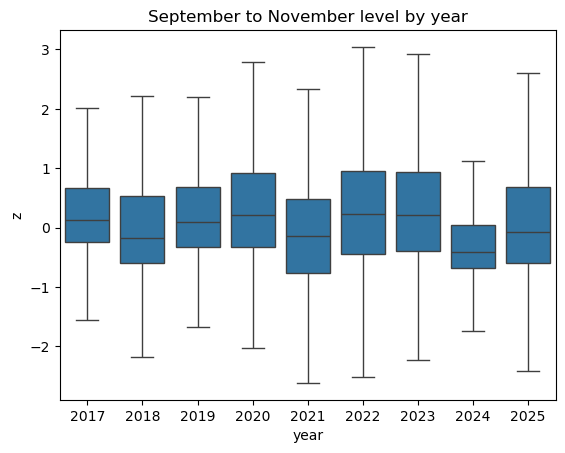

In [20]:
autumn = train_df[train_df["month"].isin([9, 10, 11])]
sns.boxplot(data = autumn, x = "year", y = "z", showfliers = False)
plt.title("September to November level by year")
plt.show()

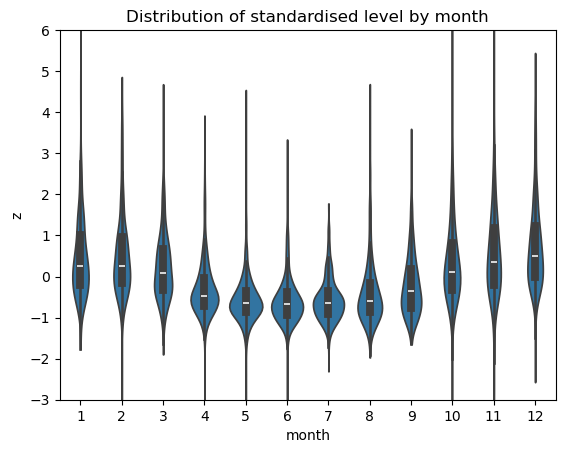

In [21]:
sns.violinplot(data = sample, x = "month", y = "z", cut = 0)
plt.ylim(-3, 6)
plt.title("Distribution of standardised level by month")
plt.show()

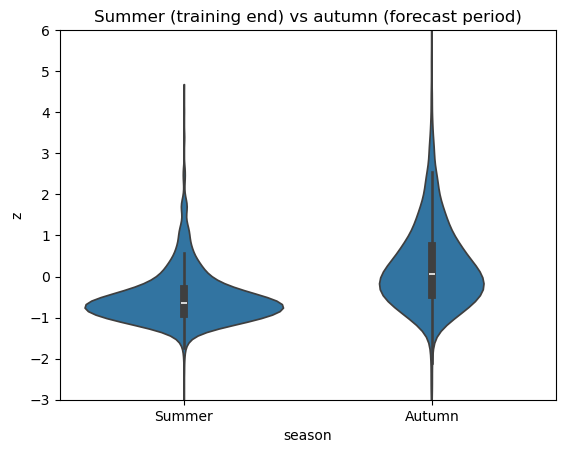

In [22]:
# TO REMEMBER: i used this idea from claude !!!
sample["season"] = sample["month"].map({6: "Summer", 7: "Summer", 8: "Summer",
                                        9: "Autumn", 10: "Autumn", 11: "Autumn"})

sns.violinplot(data = sample.dropna(subset = ["season"]), x = "season", y = "z", cut = 0)
plt.ylim(-3, 6)
plt.title("Summer (training end) vs autumn (forecast period)")
plt.show()

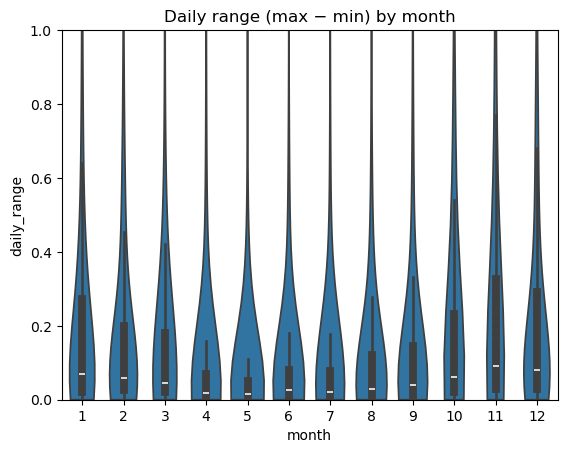

In [23]:
sample["daily_range"] = sample["max"] - sample["min"]

sns.violinplot(data = sample, x = "month", y = "daily_range", cut = 0)
plt.ylim(0, 1)
plt.title("Daily range (max − min) by month")
plt.show()

We create a baseline model

In [24]:
# i used function from lab 5
def get_coefs(m, plot = False, feature_names = None, figsize = (5,5), figtitle = None, intercept = True):
    """Returns model coefficients in a data frame for a fitted linear model.
    
    Args:
        m: sklearn LinearRegression model object or pipeline with LinearRegression as final step
        plot: boolean value, should coefficients be plotted with error bars
        feature_names: list of feature names to use in the plot 
        figsize: tuple defining figure size
        figtitle: string defining figure title
        intercept: boolean value, should intercept be included in the plot
    """
    
    # Extract intercept and coefficients into a single array
    w = np.concatenate(([m[-1].intercept_] if isinstance(m, sklearn.pipeline.Pipeline) else [m.intercept_], 
                            m[-1].coef_ if isinstance(m, sklearn.pipeline.Pipeline) else m.coef_))
    # Extract name of features
    if feature_names is None:
        feature_names = m[:-1].get_feature_names_out() if isinstance(m, sklearn.pipeline.Pipeline) else m.feature_names_in_
    feature_names = np.concatenate((['intercept'], feature_names))
    # Create a data frame
    w_df = pd.DataFrame({'feature': feature_names, 'coef': w}).sort_values ("coef", ascending=False)

    if plot:
        if not intercept:
            w_df = w_df[w_df['feature'] != 'intercept']
        plt.figure(figsize=figsize)
        plt.barh(w_df['feature'], w_df['coef'])
        plt.ylabel('Features')
        plt.xlabel('Coefficient Value')
        plt.axvline(x=0, color=".5")
        if figtitle is not None:
            plt.title(figtitle)
        plt.grid()
        plt.show()
    
    return  w_df




In [25]:
"""lm = LinearRegression().fit(X_train, y_train)
w_df = get_coefs(lm, plot=True, figsize=(6,6), figtitle="Linear Regression", intercept=False)"""

'lm = LinearRegression().fit(X_train, y_train)\nw_df = get_coefs(lm, plot=True, figsize=(6,6), figtitle="Linear Regression", intercept=False)'

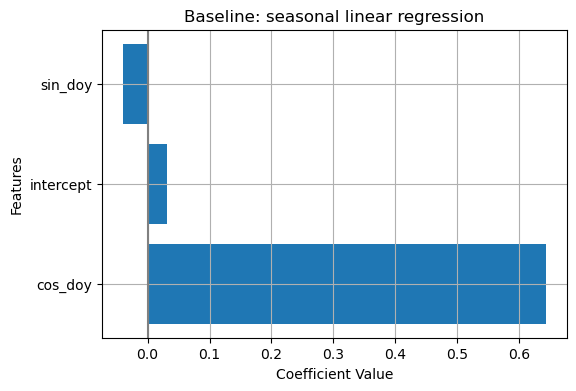

     feature      coef
2    cos_doy  0.642904
0  intercept  0.031520
1    sin_doy -0.039613


In [26]:
river_feat = add_features(river_long3)
X_train, y_train, X_test, y_test = make_split(river_feat, feature_cols = ["sin_doy", "cos_doy"], target = "z")

lm = LinearRegression().fit(X_train, y_train)
w_df = get_coefs(lm, plot = True, figsize = (6, 4), figtitle = "Baseline: seasonal linear regression")
print(w_df)

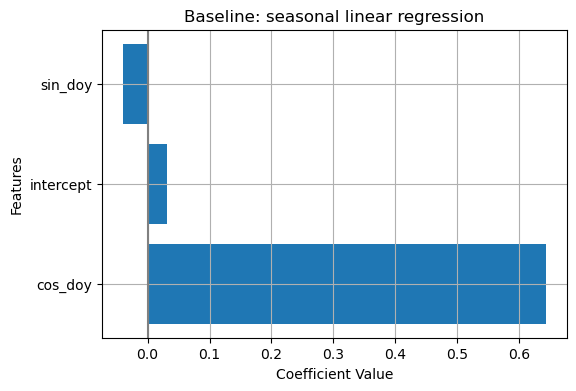

     feature      coef
2    cos_doy  0.642904
0  intercept  0.031520
1    sin_doy -0.039613


In [27]:
lm = LinearRegression().fit(X_train, y_train)
w_df = get_coefs(lm, plot = True, figsize = (6, 4), figtitle = "Baseline: seasonal linear regression")
print(w_df)

In [28]:
years = [2022, 2023, 2024, 2025]
base_scores = cv_score(LinearRegression(), river_long3, years, ["sin_doy", "cos_doy"])

print(base_scores)
print(base_scores.mean())
print(base_scores.std(ddof = 1))

[1.1316489  1.31423058 0.88879552 1.00777058]
1.0856113964854972
0.18182580007469018


In [29]:

test_df = (river_feat[river_feat["date"] > cutoff]
           .dropna(subset = ["z"])
           .sort_values(["Observation_ID", "date"])
           .reset_index(drop = True))

pred_z = lm.predict(X_test)
pred_m = pred_z * test_df["sta_std"] + test_df["sta_mean"]

print("RMSE (z):", root_mean_squared_error(y_test, pred_z))
print("RMSE (m):", root_mean_squared_error(test_df["avg"], pred_m))
print("MAE (m): ", mean_absolute_error(test_df["avg"], pred_m))

RMSE (z): 0.9506225557297677
RMSE (m): 0.19523295173035227
MAE (m):  0.1367635833603188


### Poylnomial Features

In [30]:
preprocesser = make_column_transformer(
    ("passthrough", ["sin_doy", "cos_doy"]),
    (StandardScaler(), ["Latitude", "Longitude"]),
    verbose_feature_names_out = False
)     

poly_pipe = make_pipeline(
    preprocesser,
    PolynomialFeatures(degree = 2, include_bias = False),
    Ridge(alpha = 1.0)
)

cv_scores = cv_score(poly_pipe, river_long3, [2022, 2023, 2024, 2025], ["sin_doy", "cos_doy", "Latitude", "Longitude"])

print(cv_scores)
print(cv_scores.mean())
print(cv_scores.std(ddof = 1))

[1.14626686 1.32369239 0.88207967 1.00114694]
1.0882964620325262
0.19051877788444116


## fit and val

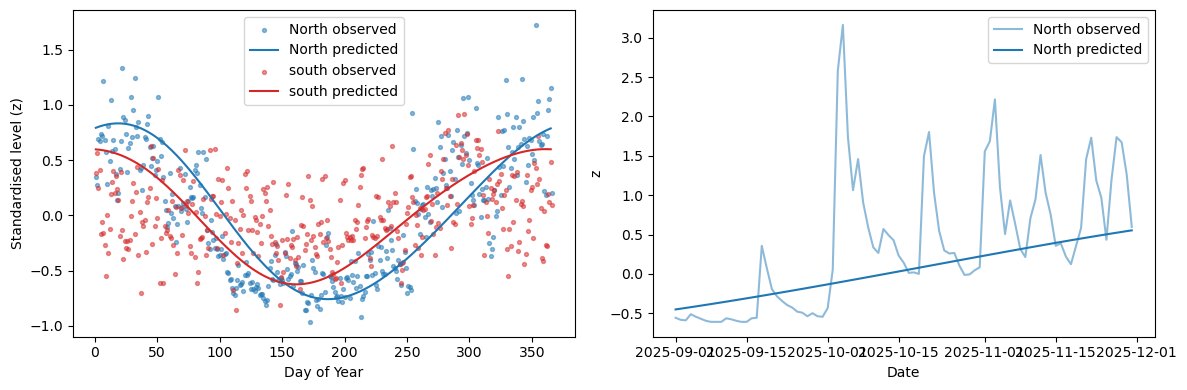

In [31]:
fit, val = make_fold(river_long3, 2025)
feats = ["sin_doy", "cos_doy", "Latitude", "Longitude"]
poly_pipe.fit(fit[feats], fit["z"])

lat = fit.groupby("Observation_ID", observed = True)["Latitude"].first()
north = lat.idxmax()
south = lat.idxmin()

def year_grid(station_id, df):
    row = df[df["Observation_ID"] == station_id].iloc[0]
    grid = pd.DataFrame({"doy": np.arange(1, 366)})
    grid["sin_doy"] = np.sin(2 * np.pi * grid["doy"] / 365.25)
    grid["cos_doy"] = np.cos(2 * np.pi * grid["doy"] / 365.25)
    grid["Latitude"] = row["Latitude"]
    grid["Longitude"] = row["Longitude"]
    return grid

def observed_avg(station_id, df):
    s = df[df["Observation_ID"] == station_id]
    return s.groupby(s["date"].dt.dayofyear)["z"].mean()

fig, ax = plt.subplots(1, 2, figsize = (12, 4))
for sid, colour, name in [(north, "tab:blue", "North"), (south, "tab:red", "south")]:
    g = year_grid(sid, fit)
    obs = observed_avg(sid, fit)
    ax[0].scatter(obs.index, obs.values, s=8, color = colour, alpha = 0.5, label = f"{name} observed")
    ax[0].plot(g["doy"], poly_pipe.predict(g[feats]), color = colour, label = f"{name} predicted")


ax[0].set_xlabel("Day of Year")
ax[0].set_ylabel("Standardised level (z)")
ax[0].legend() 

v = val[val["Observation_ID"] == north].sort_values("date")
ax[1].plot(v["date"], v["z"], color = "tab:blue", alpha = 0.5, label = "North observed")
ax[1].plot(v["date"], poly_pipe.predict(v[feats]), color = "tab:blue", label = "North predicted")
ax[1].set_xlabel("Date")
ax[1].set_ylabel("z")
ax[1].legend()

plt.tight_layout()
plt.show()

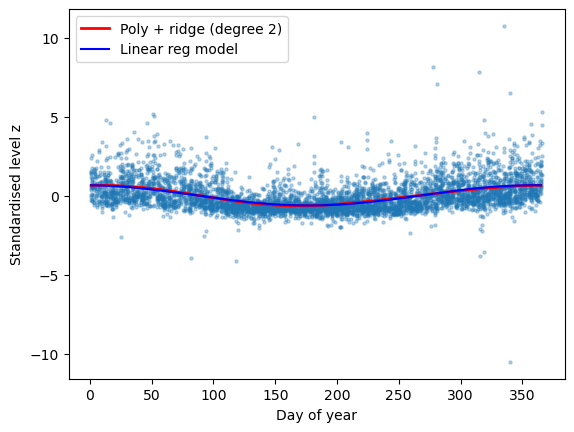

In [32]:
sample = fit.sample(5000, random_state = 0)
plt.scatter(sample["date"].dt.dayofyear,
            sample["z"],
            s=5,
            alpha = 0.3
)

grid = pd.DataFrame({"doy": np.arange(1, 366)})
grid["cos_doy"] = np.cos(2 * np.pi * grid["doy"] / 365.25)
grid["sin_doy"] = np.sin(2 * np.pi * grid["doy"] / 365.25)

grid["Latitude"] = fit["Latitude"].median()
grid["Longitude"] = fit["Longitude"].median()

plt.plot(
    grid["doy"], poly_pipe.predict(grid[feats]),
    color = "red",
    linewidth = 2,
    label = "Poly + ridge (degree 2)"
)
lm.fit(fit[["sin_doy", "cos_doy"]], fit["z"])
plt.plot(
    grid["doy"], lm.predict(grid[["sin_doy", "cos_doy"]]),
    color = "blue",
    label = "Linear reg model"
)

plt.xlabel("Day of year")
plt.ylabel("Standardised level z")
plt.legend()
plt.show()

## Tuning

In [33]:
degs = [1, 2, 3, 4]
alphas = np.logspace(-2, 3, 6)
ws = []
results = []

for d in degs:
    for a in alphas:
        preprocesser = make_column_transformer(
        ("passthrough", ["sin_doy", "cos_doy"]),
        (StandardScaler(), ["Latitude", "Longitude"]),
        verbose_feature_names_out = False
        )     

        poly_pipe = make_pipeline(
            preprocesser,
            PolynomialFeatures(degree = d, include_bias = False),
            Ridge(alpha = a)
        )

        cv_scores = cv_score(poly_pipe, river_long3, [2022, 2023, 2024, 2025], ["sin_doy", "cos_doy", "Latitude", "Longitude"])
        print("_"*10)
        print("Deg:", d, "| Alpha:", a)
        print("-"*10)
        ws.append(poly_pipe[-1].coef_)
        results.append({"degree": d, "alpha": a, 
                        "cv_mean": cv_scores.mean(), "cv_sd": cv_scores.std(ddof = 1)})

res = pd.DataFrame(results)

__________
Deg: 1 | Alpha: 0.01
----------
__________
Deg: 1 | Alpha: 0.1
----------
__________
Deg: 1 | Alpha: 1.0
----------
__________
Deg: 1 | Alpha: 10.0
----------
__________
Deg: 1 | Alpha: 100.0
----------
__________
Deg: 1 | Alpha: 1000.0
----------
__________
Deg: 2 | Alpha: 0.01
----------
__________
Deg: 2 | Alpha: 0.1
----------
__________
Deg: 2 | Alpha: 1.0
----------
__________
Deg: 2 | Alpha: 10.0
----------
__________
Deg: 2 | Alpha: 100.0
----------
__________
Deg: 2 | Alpha: 1000.0
----------
__________
Deg: 3 | Alpha: 0.01
----------
__________
Deg: 3 | Alpha: 0.1
----------
__________
Deg: 3 | Alpha: 1.0
----------
__________
Deg: 3 | Alpha: 10.0
----------
__________
Deg: 3 | Alpha: 100.0
----------
__________
Deg: 3 | Alpha: 1000.0
----------
__________
Deg: 4 | Alpha: 0.01
----------
__________
Deg: 4 | Alpha: 0.1
----------
__________
Deg: 4 | Alpha: 1.0
----------
__________
Deg: 4 | Alpha: 10.0
----------
__________
Deg: 4 | Alpha: 100.0
----------
_________

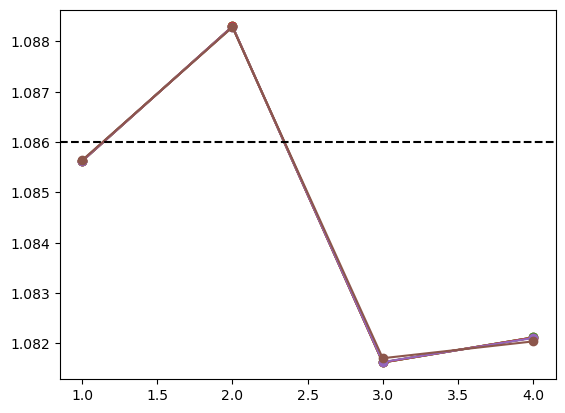

In [34]:
for a in alphas:
    r = res[res["alpha"] == a]
    plt.plot(r["degree"], r["cv_mean"], marker = "o", label = f"alpha = {a:g}")
plt.axhline(1.086, color = "k", linestyle = "--", label = "Baseline")

In [35]:
res.sort_values("cv_mean").head(8)


,degree,alpha,cv_mean,cv_sd
12,3,0.01,1.081621,0.167635
13,3,0.10,1.081621,0.167635
14,3,1.00,1.081621,0.167635
15,3,10.00,1.081622,0.167642
16,3,100.00,1.081630,0.167709
17,3,1000.00,1.081706,0.168365
23,4,1000.00,1.082040,0.167536
22,4,100.00,1.082108,0.167018


In [36]:
years = [2022, 2023, 2024, 2025]
base_scores = cv_score(LinearRegression(), river_long3, years, ["sin_doy", "cos_doy"])
preprocesser = make_column_transformer(
        ("passthrough", ["sin_doy", "cos_doy"]),
        (StandardScaler(), ["Latitude", "Longitude"]),
        verbose_feature_names_out = False
        )     

poly_pipe = make_pipeline(
            preprocesser,
            PolynomialFeatures(degree = 3, include_bias = False),
            Ridge(alpha = 1)
        )
poly3_scores = cv_score(poly_pipe, river_long3, years, feats)
print(poly3_scores - base_scores)

[-0.00828215 -0.01826951  0.02101799 -0.01042657]


# Kernalised ridge regression

In [38]:
from sklearn.kernel_ridge import KernelRidge
krr_pipe = make_pipeline(
    preprocesser,
    KernelRidge(kernel = "rbf", alpha = 1, gamma = 1)
)
krr_scores = cv_score(krr_pipe, river_long3, years, feats, n_sub = 3000)
print(krr_scores)

[1.16483063 1.31735833 0.98911577 0.99675902]


Tuning

In [39]:
alphas = np.logspace(-2, 2, 5)

gammas = [0.01, 0.1, 1, 10]

results = []

for a in alphas:
    for g in gammas:
        preprocesser = make_column_transformer(
        ("passthrough", ["sin_doy", "cos_doy"]),
        (StandardScaler(), ["Latitude", "Longitude"]),
        verbose_feature_names_out = False
        )     

        krr_pipe = make_pipeline(
            preprocesser,
            KernelRidge(kernel = "rbf", alpha = a, gamma = g)
        )
        krr_scores = cv_score(krr_pipe, river_long3, years, feats, n_sub = 3000)
        print("_"*10)
        print("Alpha:", a, "| Gamma:", g)
        print("-"*10)
        results.append({"alpha": a, "gamma": g, 
                        "cv_mean": krr_scores.mean(), "cv_sd": krr_scores.std(ddof = 1)})

res_krr = pd.DataFrame(results)
res_krr.sort_values("cv_mean").head(5)

__________
Alpha: 0.01 | Gamma: 0.01
----------
__________
Alpha: 0.01 | Gamma: 0.1
----------
__________
Alpha: 0.01 | Gamma: 1
----------
__________
Alpha: 0.01 | Gamma: 10
----------
__________
Alpha: 0.1 | Gamma: 0.01
----------
__________
Alpha: 0.1 | Gamma: 0.1
----------
__________
Alpha: 0.1 | Gamma: 1
----------
__________
Alpha: 0.1 | Gamma: 10
----------
__________
Alpha: 1.0 | Gamma: 0.01
----------
__________
Alpha: 1.0 | Gamma: 0.1
----------
__________
Alpha: 1.0 | Gamma: 1
----------
__________
Alpha: 1.0 | Gamma: 10
----------
__________
Alpha: 10.0 | Gamma: 0.01
----------
__________
Alpha: 10.0 | Gamma: 0.1
----------
__________
Alpha: 10.0 | Gamma: 1
----------
__________
Alpha: 10.0 | Gamma: 10
----------
__________
Alpha: 100.0 | Gamma: 0.01
----------
__________
Alpha: 100.0 | Gamma: 0.1
----------
__________
Alpha: 100.0 | Gamma: 1
----------
__________
Alpha: 100.0 | Gamma: 10
----------


,alpha,gamma,cv_mean,cv_sd
8,1.0,0.01,1.094997,0.180466
12,10.0,0.01,1.095024,0.204564
17,100.0,0.10,1.099442,0.215452
13,10.0,0.10,1.099995,0.183496
4,0.1,0.01,1.100359,0.179759
